# 02 — Validate the optional social turning-rate limit

**Scientific question.** Does the shared model implement the intended angular bound without changing the disabled baseline, synchronous updates, or the effect of observation frequency?

**Hypotheses.** With `max_turn_rate=14.0`, a social decision turns through the shortest signed angle by at most `14 × dt` radians. With `max_turn_rate=None` and zero noise, the exact previous instantaneous-turn pipeline is recovered. These are implementation questions; passing them does not establish timestep stability or suitability for light.

We reuse `papers/shiner_model.py`; no notebook-specific fish/model class is created. Social radii, raw social-vector combination, repulsion priority, walls and synchronous planning stay as implemented. Every model below has **360° perception and zero angular noise**. Turning assertions are evaluated away from walls. Wall reflection is tested separately because its instantaneous heading reversal is outside the social turn bound.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_three"
PAPERS = MODEL_DIR

import copy
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

if not (HERE / "data").exists() or not (HERE.parent.parent / "shiner_model.py").exists():
    raise RuntimeError("Run this notebook from its handlings/trial_three folder.")
sys.path.insert(0, str(PAPERS))
from shiner_model import GoldenShinersModel
from checks.check_support import controlled_model

DATA = HERE / "data"
FIGURES = HERE / "figures"
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
RATE = 14.0
DT_VALUES = [0.125, 0.0625, 0.03125, 0.015625, 0.0078125]
checks = []

def heading(angle):
    return np.array([np.cos(angle), np.sin(angle)])

def signed_angle(old, new):
    cross = old[0] * new[1] - old[1] * new[0]
    return float(np.arctan2(cross, np.dot(old, new)))

def state(model):
    return np.array([[*f.position, *f.direction, f.speed] for f in model.agents])

def rng_state(model):
    return (json.dumps(model.rng.bit_generator.state, sort_keys=True), model.random.getstate())

def add_check(name, passed, observed, expected, reason):
    checks.append({"Check": name, "Passed": bool(passed), "Observed": str(observed),
                   "Expected": str(expected), "WhyInformative": reason})
    assert passed, f"{name}: observed {observed}; expected {expected}"

def turning_fish(angle=0.0, dt=0.015625):
    m = controlled_model([[10., 10.]], [heading(angle)], dt=dt,
                         max_turn_rate=RATE, fov_degrees=360., angular_noise=0.)
    return m, next(iter(m.agents))

criteria = json.loads((DATA / "predeclared_criteria.json").read_text())
print("Shared, predeclared study thresholds are present:", criteria["DeclaredBeforeExperiments"])
print("This notebook runs controlled checks, not parameter selection or ensemble convergence.")

Shared, predeclared study thresholds are present: True
This notebook runs controlled checks, not parameter selection or ensemble convergence.


## Physical-time convention and scope

Puckett et al. report a maximum turn of **1.75 rad per update** at **8 updates/s** in Supplementary Table S1. We derive `1.75 / 0.125 = 14 rad/s` and scale the per-update bound as `14 × dt`. **That conversion and scaling are our implementation convention**, not a directly fitted biological rate.

At fixed `dt`, this is an intentional behavioral alternative to instantaneous social turning. It does not alter the desired direction computed from local neighbors. A very close neighbor still takes priority, but the fish may need several updates to complete the desired escape turn. Therefore the new option must also undergo the interaction-crossing and timestep checks in Notebook 03.

Sources: [Puckett et al. (2018)](https://doi.org/10.1038/s41598-018-26037-9), [official supplementary material, Table S1](https://static-content.springer.com/esm/art%3A10.1038%2Fs41598-018-26037-9/MediaObjects/41598_2018_26037_MOESM1_ESM.pdf).

In [2]:
cap_table = pd.DataFrame({"dt_s": DT_VALUES})
cap_table["MaxSocialTurnPerUpdate_rad"] = RATE * cap_table["dt_s"]
cap_table["UpdatesPerSecond"] = 1 / cap_table["dt_s"]
cap_table["MaximumTurnCapacity_rad_per_s"] = (
    cap_table["MaxSocialTurnPerUpdate_rad"] * cap_table["UpdatesPerSecond"]
)
display(cap_table)
cap_table.to_csv(DATA / "02_turn_capacity.csv", index=False)

,dt_s,MaxSocialTurnPerUpdate_rad,UpdatesPerSecond,MaximumTurnCapacity_rad_per_s
0,0.125000,1.750000,8.0,14.0
1,0.062500,0.875000,16.0,14.0
2,0.031250,0.437500,32.0,14.0
3,0.015625,0.218750,64.0,14.0
4,0.007812,0.109375,128.0,14.0


## Known-answer tests: signed turns, wrap-around and normalization

We choose headings with an analytic answer. Clockwise and counter-clockwise cases expose sign errors; crossing ±π exposes incorrect long-way rotations. Directly querying `turn_toward` isolates the social angular update from movement and reflection. Tolerances below are floating-point tolerances, not the practical study thresholds used for ensemble comparisons.

In [3]:
dt = 0.015625
limit = RATE * dt
m, fish = turning_fish()
result = fish.turn_toward(heading(0.))
add_check("01_equal_heading", np.array_equal(result, fish.direction), result.tolist(), [1., 0.],
          "A satisfied desired heading should not generate a turn.")

result = fish.turn_toward(heading(0.1))
add_check("02_target_within_bound", np.allclose(result, heading(0.1), rtol=0, atol=1e-14),
          signed_angle(fish.direction, result), 0.1,
          "Clipping must not undershoot an attainable desired direction.")

result = fish.turn_toward(heading(0.9))
add_check("03_target_beyond_bound", np.isclose(signed_angle(fish.direction, result), limit, rtol=0, atol=1e-14),
          signed_angle(fish.direction, result), limit,
          "An unattainable target should use exactly the per-update angular capacity.")

result = fish.turn_toward(heading(-0.9))
add_check("04_clockwise", np.isclose(signed_angle(fish.direction, result), -limit, rtol=0, atol=1e-14),
          signed_angle(fish.direction, result), -limit,
          "The bound must preserve the shortest-turn clockwise sign.")

result = fish.turn_toward(heading(0.9))
add_check("05_counterclockwise", np.isclose(signed_angle(fish.direction, result), limit, rtol=0, atol=1e-14),
          signed_angle(fish.direction, result), limit,
          "The bound must preserve the shortest-turn counter-clockwise sign.")

wrap_results = []
for old_degrees, target_degrees, expected_degrees in [(179., -179., 2.), (-179., 179., -2.)]:
    _, f = turning_fish(np.deg2rad(old_degrees))
    new = f.turn_toward(heading(np.deg2rad(target_degrees)))
    wrap_results.append(signed_angle(f.direction, new))
expected_wrap = np.deg2rad([2., -2.])
add_check("06_wrap_both_directions", np.allclose(wrap_results, expected_wrap, rtol=0, atol=1e-14),
          np.rad2deg(wrap_results).tolist(), [2., -2.],
          "Nearby headings across ±π must not trigger an almost-full revolution.")

norm_errors = []
for old_angle in np.linspace(-np.pi, np.pi, 17):
    _, f = turning_fish(old_angle)
    for target_angle in np.linspace(-np.pi, np.pi, 19):
        norm_errors.append(abs(np.linalg.norm(f.turn_toward(heading(target_angle))) - 1.))
add_check("07_unit_headings", max(norm_errors) < 1e-14, max(norm_errors), "norm error < 1e-14 across 323 angular pairs",
          "Unit headings preserve the intended constant speed during movement.")

## One second of maximal social turning

For each internal `dt`, we repeatedly set the desired heading **2.5 radians ahead of the current heading**. This remains beyond every tested per-update cap and below π, so the known answer is a continuous counter-clockwise turn totaling 14 radians in one second. This is a capacity test with a deliberately changing target; a fixed target would be reached and would no longer request maximum turning.

Accumulated signed increments measure total turn rather than the final angle modulo 2π. Equal turning capacity does not imply equal trajectories or equal emergent group behavior.

,dt_s,Updates,AccumulatedTurn_rad,MaximumIncrement_rad
0,0.125000,8,14.0,1.750000
1,0.062500,16,14.0,0.875000
2,0.031250,32,14.0,0.437500
3,0.015625,64,14.0,0.218750
4,0.007812,128,14.0,0.109375


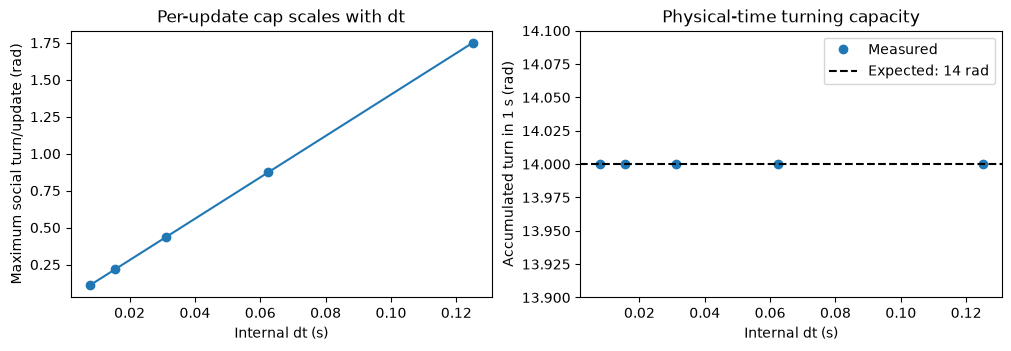

In [4]:
capacity_results = []
for dt in DT_VALUES:
    _, f = turning_fish(dt=dt)
    increments = []
    for _ in range(round(1 / dt)):
        old = f.direction.copy()
        target = heading(np.arctan2(old[1], old[0]) + 2.5)
        f.direction = f.turn_toward(target)
        increments.append(signed_angle(old, f.direction))
    capacity_results.append({"dt_s": dt, "Updates": len(increments),
                             "AccumulatedTurn_rad": sum(increments),
                             "MaximumIncrement_rad": max(increments)})
capacity_results = pd.DataFrame(capacity_results)
add_check("08_one_second_dt_scaling", np.allclose(capacity_results["AccumulatedTurn_rad"], RATE, rtol=0, atol=1e-12),
          capacity_results["AccumulatedTurn_rad"].tolist(), "14 radians at every dt",
          "Changing the update frequency preserves maximum social turning capacity per physical second.")
display(capacity_results)
capacity_results.to_csv(DATA / "02_one_second_turns.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].plot(cap_table["dt_s"], cap_table["MaxSocialTurnPerUpdate_rad"], "o-")
axes[0].set(xlabel="Internal dt (s)", ylabel="Maximum social turn/update (rad)", title="Per-update cap scales with dt")
axes[1].plot(capacity_results["dt_s"], capacity_results["AccumulatedTurn_rad"], "o", label="Measured")
axes[1].axhline(RATE, color="black", linestyle="--", label="Expected: 14 rad")
axes[1].set(xlabel="Internal dt (s)", ylabel="Accumulated turn in 1 s (rad)", ylim=(13.9, 14.1), title="Physical-time turning capacity")
axes[1].legend()
fig.savefig(FIGURES / "02_turn_capacity.png", dpi=160)
plt.show()

## Exact disabled-option regression and synchronous planning

For regression, two models start from the same random state. The reference model replaces only `turn_toward` with the old identity operation (`desired → adopted`), reusing the shared social rules, motion and observer. We compare complete recorded fish trajectories, model metrics, clocks and RNG states, not just a final group metric. This tests the newly optional transformation against the former instantaneous-turn pipeline without maintaining a copied model. It does not independently revalidate every pre-existing social rule.

For synchronization, we hold a controlled three-fish configuration, plan all updates, and check that every current state stays unchanged until `advance`. Reversing the planning order must give identical plans. This detects accidental use of another fish's partially updated position or heading.

In [5]:
regressions = []
for seed in [0, 2]:
    for speed in [1., 5.]:
        tested = GoldenShinersModel(seed=seed, speed=speed, dt=0.125, max_turn_rate=None,
                                    fov_degrees=360., angular_noise=0.)
        reference = GoldenShinersModel(seed=seed, speed=speed, dt=0.125, max_turn_rate=None,
                                       fov_degrees=360., angular_noise=0.)
        for f in reference.agents:
            f.turn_toward = lambda target: target
        exact_every_update = np.array_equal(state(tested), state(reference))
        for _ in range(100):
            tested.step()
            reference.step()
            exact_every_update &= np.array_equal(state(tested), state(reference))
        pd.testing.assert_frame_equal(tested.datacollector.get_model_vars_dataframe(),
                                      reference.datacollector.get_model_vars_dataframe(), check_exact=True)
        pd.testing.assert_frame_equal(tested.datacollector.get_agent_vars_dataframe(),
                                      reference.datacollector.get_agent_vars_dataframe(), check_exact=True)
        identical_rng = rng_state(tested) == rng_state(reference)
        regressions.append({"Seed": seed, "Speed_BL_s": speed, "Updates": 100,
                            "AllInternalStatesBitwiseEqual": bool(exact_every_update),
                            "RecordedDataExactlyEqual": True, "RNGExactlyEqual": identical_rng})
regressions = pd.DataFrame(regressions)
backwards_compatible = bool(regressions[["AllInternalStatesBitwiseEqual", "RecordedDataExactlyEqual", "RNGExactlyEqual"]].all().all())
add_check("09_disabled_baseline_exact", backwards_compatible,
          regressions.to_dict("records"), "exact trajectories, observations and RNG for all four paired cases",
          "The optional turning feature must preserve existing deterministic baseline evidence when disabled.")
display(regressions)
regressions.to_csv(DATA / "02_disabled_baseline_regression.csv", index=False)

positions = [[10., 10.], [11., 10.], [14., 10.]]
directions = [heading(0.), heading(np.pi / 2), heading(np.pi)]
forward = controlled_model(positions, directions, dt=0.015625, max_turn_rate=RATE)
reverse = controlled_model(positions, directions, dt=0.015625, max_turn_rate=RATE)
old = state(forward).copy()
for f in forward.agents:
    f.decide()
unchanged_during_planning = np.array_equal(old, state(forward))
for f in reversed(list(reverse.agents)):
    f.decide()
plans_forward = np.array([[*f.next_position, *f.next_direction, f.speed] for f in forward.agents])
plans_reverse = np.array([[*f.next_position, *f.next_direction, f.speed] for f in reverse.agents])
order_independent = np.array_equal(plans_forward, plans_reverse)
for f in forward.agents:
    f.advance()
commits_planned_states = np.array_equal(state(forward), plans_forward)
add_check("10_synchronous_decide_advance", unchanged_during_planning and order_independent and commits_planned_states,
          {"OldStatesUnchanged": unchanged_during_planning, "PlanningOrderIndependent": order_independent,
           "AdvanceCommitsPlans": commits_planned_states}, "all three True",
          "Every social decision must use the same previous state before any fish commits its movement.")

,Seed,Speed_BL_s,Updates,AllInternalStatesBitwiseEqual,RecordedDataExactlyEqual,RNGExactlyEqual
0,0,1.0,100,True,True,True
1,0,5.0,100,True,True,True
2,2,1.0,100,True,True,True
3,2,5.0,100,True,True,True


## Wall response remains a separate instantaneous reflection

A single fish aimed toward a nearby wall has zero social turn. Its proposed movement crosses the boundary, so reflection reverses its heading by π. That exceeds `14 × dt` and is **expected**: the cap limits social steering before the pre-existing hard-wall response. Thus the complete model is not a globally smooth, bounded-angular-velocity system at walls. This retained boundary convention must be disclosed when interpreting convergence results.

In [6]:
wall = controlled_model([[19.99, 10.]], [heading(0.)], dt=0.015625, speed=5., max_turn_rate=RATE)
f = next(iter(wall.agents))
old_direction = f.direction.copy()
social_direction = f.turn_toward(f.social_direction(f.get_neighbors()))
social_turn = abs(signed_angle(old_direction, social_direction))
f.decide()
wall_turn = abs(signed_angle(old_direction, f.next_direction))
wall_ok = social_turn == 0 and np.isclose(wall_turn, np.pi) and np.all(f.next_position >= 0) and np.all(f.next_position <= 20)
add_check("11_wall_reflection_separate", wall_ok,
          {"SocialTurn_rad": social_turn, "TotalReflectedTurn_rad": wall_turn,
           "NextPosition": f.next_position.tolist()}, "zero social turn; π wall reversal; position inside arena",
          "Pre-existing wall reflection is retained and is not constrained by the social turning option.")
print("Social turn:", social_turn, "rad; reflected heading change:", wall_turn, "rad.")

Social turn: 0.0 rad; reflected heading change: 3.141592653589793 rad.


## Recording interval is an observation choice

At internal `dt = 0.015625 s`, saving every eighth update records every `0.125 s`. Two identical rate-limited, noise-free simulations are advanced for **10 physical seconds at 5 BL/s**. We compare states at **every internal update**, then compare every retained model and fish row and both RNG states exactly. Sparse recording is not used to skip simulation updates. Notebook 03 evaluates event-sensitive diagnostics at every internal update, independently of this storage interval.

In [7]:
full = GoldenShinersModel(seed=7, speed=5., dt=0.015625, max_turn_rate=RATE,
                          record_every=1, fov_degrees=360., angular_noise=0.)
sparse = GoldenShinersModel(seed=7, speed=5., dt=0.015625, max_turn_rate=RATE,
                            record_every=8, fov_degrees=360., angular_noise=0.)
steps = round(10 / full.dt)
all_internal_states_exact = np.array_equal(state(full), state(sparse))
for _ in range(steps):
    full.step()
    sparse.step()
    all_internal_states_exact &= np.array_equal(state(full), state(sparse))
full_group = full.datacollector.get_model_vars_dataframe()
sparse_group = sparse.datacollector.get_model_vars_dataframe()
pd.testing.assert_frame_equal(full_group.iloc[::8].reset_index(drop=True), sparse_group, check_exact=True)
full_fish = full.datacollector.get_agent_vars_dataframe()
sparse_fish = sparse.datacollector.get_agent_vars_dataframe()
retained_steps = sparse.recorded_steps
pd.testing.assert_frame_equal(full_fish.loc[retained_steps], sparse_fish, check_exact=True)
stride_rng_exact = rng_state(full) == rng_state(sparse)
stride_ok = bool(all_internal_states_exact and stride_rng_exact and full.steps == sparse.steps == steps)
stride_info = {"InternalDt_s": full.dt, "RecordingInterval_s": sparse.record_every * sparse.dt,
               "Duration_s": 10., "Speed_BL_s": 5., "Seed": 7, "InternalUpdatesPerModel": steps,
               "FullGroupRows": len(full_group), "SparseGroupRows": len(sparse_group),
               "FullFishRows": len(full_fish), "SparseFishRows": len(sparse_fish),
               "AllInternalStatesBitwiseEqual": bool(all_internal_states_exact),
               "RetainedGroupRowsExactlyEqual": True, "RetainedFishRowsExactlyEqual": True,
               "RNGExactlyEqual": stride_rng_exact}
add_check("12_recording_stride_observer_only", stride_ok, stride_info,
          "identical internal states, retained observations and RNG",
          "Reducing storage must not change physical dynamics or random-number consumption.")
display(pd.DataFrame([stride_info]))

,InternalDt_s,RecordingInterval_s,Duration_s,Speed_BL_s,Seed,InternalUpdatesPerModel,FullGroupRows,SparseGroupRows,FullFishRows,SparseFishRows,AllInternalStatesBitwiseEqual,RetainedGroupRowsExactlyEqual,RetainedFishRowsExactlyEqual,RNGExactlyEqual
0,0.015625,0.125,10.0,5.0,7,640,641,81,12820,1620,True,True,True,True


## Findings and limits

The executed results below answer implementation questions. The 14-rad/s option is accepted for the **next experiment**, while `None` remains the exact disabled baseline. This is not a decision to adopt bounded turning for the final social protocol: only Notebook 03 and the predeclared comparisons can make that decision.

The angular checks use synthetic targets and one isolated fish; the synchronization fixture has three fish; the exact regression and stride checks use the full 20-fish model. Exact equality in the finite regressions protects these cases, not every possible floating-point platform or future modification. No FOV restriction, social noise, light or social-parameter search was added. Boundary reflections remain instantaneous.

In [8]:
checks_table = pd.DataFrame(checks)
display(checks_table[["Check", "Passed", "Observed", "Expected"]])
checks_table.to_csv(DATA / "02_implementation_checks.csv", index=False)
findings = {
    "AllChecksPassed": bool(checks_table["Passed"].all()),
    "ChecksPassed": int(checks_table["Passed"].sum()),
    "ChecksTotal": len(checks_table),
    "BackwardsCompatible": backwards_compatible,
    "RecordingStrideValidated": stride_ok,
    "SynchronousPlanningValidated": bool(unchanged_during_planning and order_independent and commits_planned_states),
    "MaxSocialTurnRate_rad_s": RATE,
    "LiteratureReferenceMaxTurn_rad_update": 1.75,
    "LiteratureReferenceDt_s": 0.125,
    "ScalingStatus": "14 rad/s and dt scaling are our derived implementation convention, not a fitted literature parameter.",
    "FOV_degrees": 360., "AngularNoise_rad": 0.,
    "WallReflection": "Instantaneous hard-wall response remains outside the social turn cap.",
    "OneSecondAccumulatedTurns": capacity_results.to_dict("records"),
    "DisabledBaselineRegression": regressions.to_dict("records"),
    "RecordingStride": stride_info,
    "Interpretation": "Implementation checks pass. Practical temporal stability and light readiness remain separate decisions in notebooks 03 and 04.",
    "FullModelPairedRegressionRuns": 8,
    "FullModelRecordingStrideRuns": 2,
    "ScientificCohortRuns": 0,
}
(DATA / "02_implementation_findings.json").write_text(json.dumps(findings, indent=2) + "\n")
print(f"{findings['ChecksPassed']}/{findings['ChecksTotal']} controlled implementation checks passed.")
print("None reproduces the previous pipeline exactly in all four paired regression cases.")
print("Saving every eight updates preserves every internal state and retained record exactly.")
print("Maximum accumulated social turn in one second is 14 rad at all five dt values.")
print("Wall reflection remains instantaneous; timestep stability and light readiness are not established here.")

,Check,Passed,Observed,Expected
0,01_equal_heading,True,"[1.0, 0.0]","[1.0, 0.0]"
1,02_target_within_bound,True,0.09999999999999996,0.1
2,03_target_beyond_bound,True,0.21875,0.21875
3,04_clockwise,True,-0.21875,-0.21875
4,05_counterclockwise,True,0.21875,0.21875
5,06_wrap_both_directions,True,"[2.0000000000000027, -2.0000000000000027]","[2.0, -2.0]"
6,07_unit_headings,True,1.1102230246251565e-16,norm error < 1e-14 across 323 angular pairs
7,08_one_second_dt_scaling,True,"[14.0, 14.0, 14.0, 14.0, 14.0]",14 radians at every dt
8,09_disabled_baseline_exact,True,"[{'Seed': 0, 'Speed_BL_s': 1.0, 'Updates': 100...","exact trajectories, observations and RNG for a..."
9,10_synchronous_decide_advance,True,"{'OldStatesUnchanged': True, 'PlanningOrderInd...",all three True


12/12 controlled implementation checks passed.
None reproduces the previous pipeline exactly in all four paired regression cases.
Saving every eight updates preserves every internal state and retained record exactly.
Maximum accumulated social turn in one second is 14 rad at all five dt values.
Wall reflection remains instantaneous; timestep stability and light readiness are not established here.
